<a href="https://colab.research.google.com/github/shivamkumar359/3rd-SEM-CLASS-CODES/blob/main/ML_W_10_PRACITCAL_SESSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
# customer segmentation practical
# K-MEAN + DBSCAN + INETERACTIVE

In [28]:
!pip -q install plotly

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [30]:
from google.colab import files

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [32]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mosesmoncy/mall-customerscsv")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mall-customerscsv' dataset.
Path to dataset files: /kaggle/input/mall-customerscsv


In [33]:
import os
# Locate the CSV file in the downloaded path and load it
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    df = pd.read_csv(os.path.join(path, csv_files[0]))
    print("Dataset loaded successfully!")
else:
    print("No CSV file found in the downloaded directory.")

# Display the first few rows of the dataframe
df.head()

Dataset loaded successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [34]:
print("Summary statiscs: ")
display(df.describe())

Summary statiscs: 


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [36]:
print("Missing values: ")
print(df.isnull().sum())

Missing values: 
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [37]:
print("Duplicate rows:", df.duplicated())

Duplicate rows: 0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool


<function matplotlib.pyplot.show(close=None, block=None)>

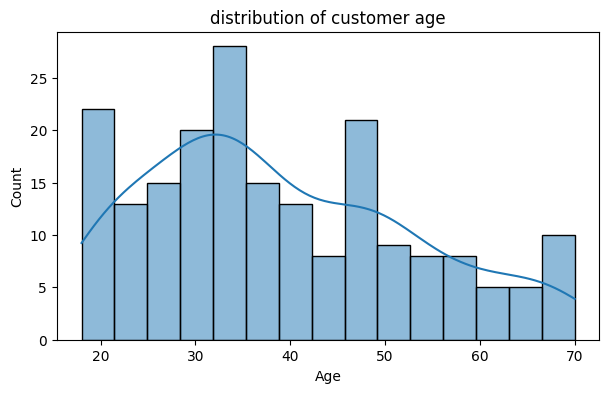

In [45]:
plt.figure(figsize=(7,4))
sns.histplot(df["Age"],bins=15, kde=True)
plt.title("distribution of customer age")

plt.show

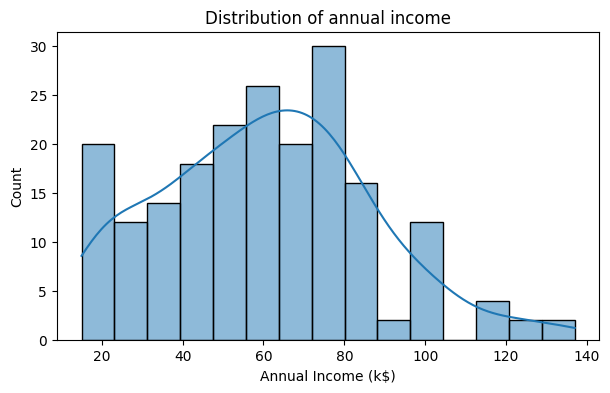

In [50]:
plt.figure(figsize=(7,4))
sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)
plt.title("Distribution of annual income")
plt.show()

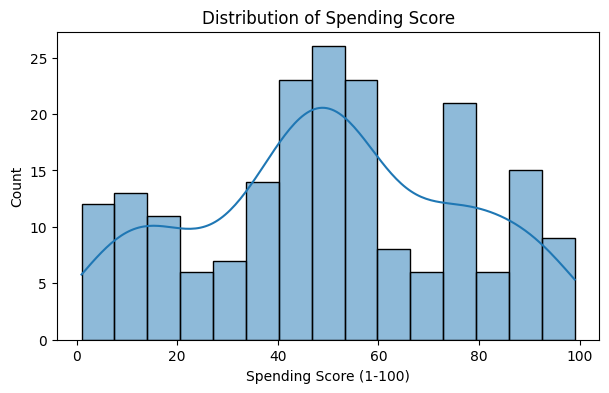

In [52]:
# spending score
plt.figure(figsize=(7,4))
sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)
plt.title("Distribution of Spending Score")
plt.show()